<div style="border:solid green 2px; padding: 20px"> <h1 style="color:green; margin-bottom:20px">Reviewer's comment v1</h1>

Hello Obed!

I'm happy to review your project today  🙌

My name is Gerardo Floresand you caan find me on Discord as **gerardo.flores.ds**

You can find my comments under the heading **«Review»**. I will categorize my comments in green, blue or red boxes like this:

<div class="alert alert-success">
    <b>Success:</b> if everything is done successfully
</div>
<div class="alert alert-warning">
    <b>Remarks:</b> if I can give some recommendations or ways to improve the project
</div>
<div class="alert alert-danger">
    <b>Needs fixing:</b> if the block requires some corrections. Work can't be accepted with the red comments
</div>

Please don't remove my comments. If you have any questions, don't hesitate to respond to my comments in a different section.
    <div class="alert alert-info"> <b>Student comments:</b> </div>    


<div style="border:solid red 2px; padding: 20px">
<b>Reviewer's comment v1</b>
    
<b>Overall Feedback</b> 

 
Another project successfully completed - well done! 🏆 Your consistent effort and progress are truly commendable.
    
Overall, well done! I can see that a lot of effort has been put in. Your project already looks really good, and you've achieved impressive results.

You’ll find specific feedback in the notebook under the **Reviewer's comment v1** sections.
    
**🚧 Suggested Tweaks & Areas for Attention**

- Add overall conclusions, as these are a very important part of any analysis.
- Update the data type for one column and slightly adjust the graph for better readability.
- Check the dataset for outliers and duplicates. Outliers can significantly affect the results of a two-sample t-test. Since the t-test compares the means of two groups, outliers can distort the mean and variance estimates, leading to unreliable test statistics and p-values.
    
Feel free to ask questions or share thoughts in the comments 👋 - I'm here to help with those finishing touches.

And also remember you can always reach out to your tutor on Discord for additional support ⛑️

You're making excellent progress on your data science journey! 🚀 You're almost there!
</div>

<div style="border:solid green 2px; padding: 20px">
<b>Reviewer's comment v2</b>
    
<b>Overall Feedback</b> 

 
Another project successfully completed - well done! 🏆 Your consistent effort and progress are truly commendable.
    
Overall, well done! I can see that a lot of effort has been put in. Your project already looks really good, and you've achieved impressive results.

You’ll find specific feedback in the notebook under the **Reviewer's comment v1** sections.
    
After performing all changes suggesed, your project is complete!

And also remember you can always reach out to your tutor on Discord for additional support ⛑️

You're making excellent progress on your data science journey! 🚀
</div>

# Project Summary: EDA & Hypothesis Testing – Chicago Taxi Rides

## Step 4: Exploratory Data Analysis (EDA)

### Objective
The objective of this project is to analyze taxi ride data in Chicago, focusing on two main aspects:

1. **Exploratory Data Analysis (EDA)** of ride patterns:
   - Identify which taxi companies had the highest ride volumes.
   - Discover the most popular drop-off neighborhoods.
   - Visualize the distributions to uncover trends and insights.

2. **Hypothesis Testing** on weather impact:
   - Determine whether ride durations from the Loop to O’Hare International Airport are significantly affected by bad weather on Saturdays.

---

## Available Datasets

1. **`project_sql_result_01.csv`**
   - `company_name`: Taxi company name  
   - `trips_amount`: Number of rides on November 15–16, 2017

2. **`project_sql_result_04.csv`**
   - `dropoff_location_name`: Neighborhood where rides ended  
   - `average_trips`: Average number of drop-offs per day in November 2017

3. **`project_sql_result_07.csv`**
   - `start_ts`: Ride start timestamp  
   - `weather_conditions`: Weather at ride start  
   - `duration_seconds`: Ride duration in seconds  
   *(Filtered to rides from the Loop to O’Hare)*

---

## Project Steps

1. **Import and inspect datasets**
2. **Clean the data** (check types, missing values, duplicates)
3. **Perform EDA**:
   - Find top taxi companies by trips
   - Find top neighborhoods by drop-offs
   - Visualize both insights with clear bar plots
4. **Test a statistical hypothesis**:
   - Compare ride durations on rainy Saturdays vs. other days
   - Use Welch’s t-test and visualize with a boxplot
5. **Summarize findings and draw actionable conclusions**

<div style="background-color: #fff3cd; color: #856404; padding: 15px; border-radius: 4px; border: 1px solid #ffeeba;">

<b>Reviewer's comment v1:</b>
    
Could you please add a brief description of the project’s goal, the steps you plan to take, and the available data? This will provide an overview of what you aim to achieve in this project.


<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v2</b>
 
Thx! Well done!.

In [1]:
#Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats
from scipy.stats import ttest_ind

In [2]:
#Load CSVs
company_df = pd.read_csv('/datasets/project_sql_result_01.csv')
neighborhood_df = pd.read_csv('/datasets/project_sql_result_04.csv')

In [3]:
#Confirm no nulls, check data types
print(company_df.info())
print(neighborhood_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64 entries, 0 to 63
Data columns (total 2 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   company_name  64 non-null     object
 1   trips_amount  64 non-null     int64 
dtypes: int64(1), object(1)
memory usage: 1.1+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   dropoff_location_name  94 non-null     object 
 1   average_trips          94 non-null     float64
dtypes: float64(1), object(1)
memory usage: 1.6+ KB
None


In [4]:
print(company_df.head())
print(neighborhood_df.head())

                      company_name  trips_amount
0                        Flash Cab         19558
1        Taxi Affiliation Services         11422
2                Medallion Leasing         10367
3                       Yellow Cab          9888
4  Taxi Affiliation Service Yellow          9299
  dropoff_location_name  average_trips
0                  Loop   10727.466667
1           River North    9523.666667
2         Streeterville    6664.666667
3             West Loop    5163.666667
4                O'Hare    2546.900000


In [5]:
company_df['trips_amount'] = company_df['trips_amount'].astype(int)

In [6]:
neighborhood_df['average_trips'] = neighborhood_df['average_trips'].astype(float)

In [7]:
# Sort companies by total trips
top_companies = company_df.sort_values('trips_amount', ascending=False)

In [8]:
print(company_df.isnull().sum())
print(neighborhood_df.isnull().sum())

company_name    0
trips_amount    0
dtype: int64
dropoff_location_name    0
average_trips            0
dtype: int64


<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
Great that you've checked data.

In [9]:
# Convert average_trips to integer — round before converting to prevent truncation
neighborhood_df['average_trips'] = neighborhood_df['average_trips'].round().astype(int)

# Recreate top 10 list using integer values
top10 = (neighborhood_df
         .sort_values('average_trips', ascending=False)
         .head(10)
         .reset_index(drop=True))

print(top10)

  dropoff_location_name  average_trips
0                  Loop          10727
1           River North           9524
2         Streeterville           6665
3             West Loop           5164
4                O'Hare           2547
5             Lake View           2421
6            Grant Park           2069
7         Museum Campus           1510
8            Gold Coast           1364
9    Sheffield & DePaul           1260


<div style="background-color: #f8d7da; color: #721c24; padding: 15px; border-radius: 4px; border: 1px solid #f5c6cb;"> 

<b>Reviewer's comment v1</b>
 
The `average_trips` column is currently a float, but it should be an integer since it represents the average number of trips. Could you please adjust its data type?

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v2</b>
 
Thx! Well done!.

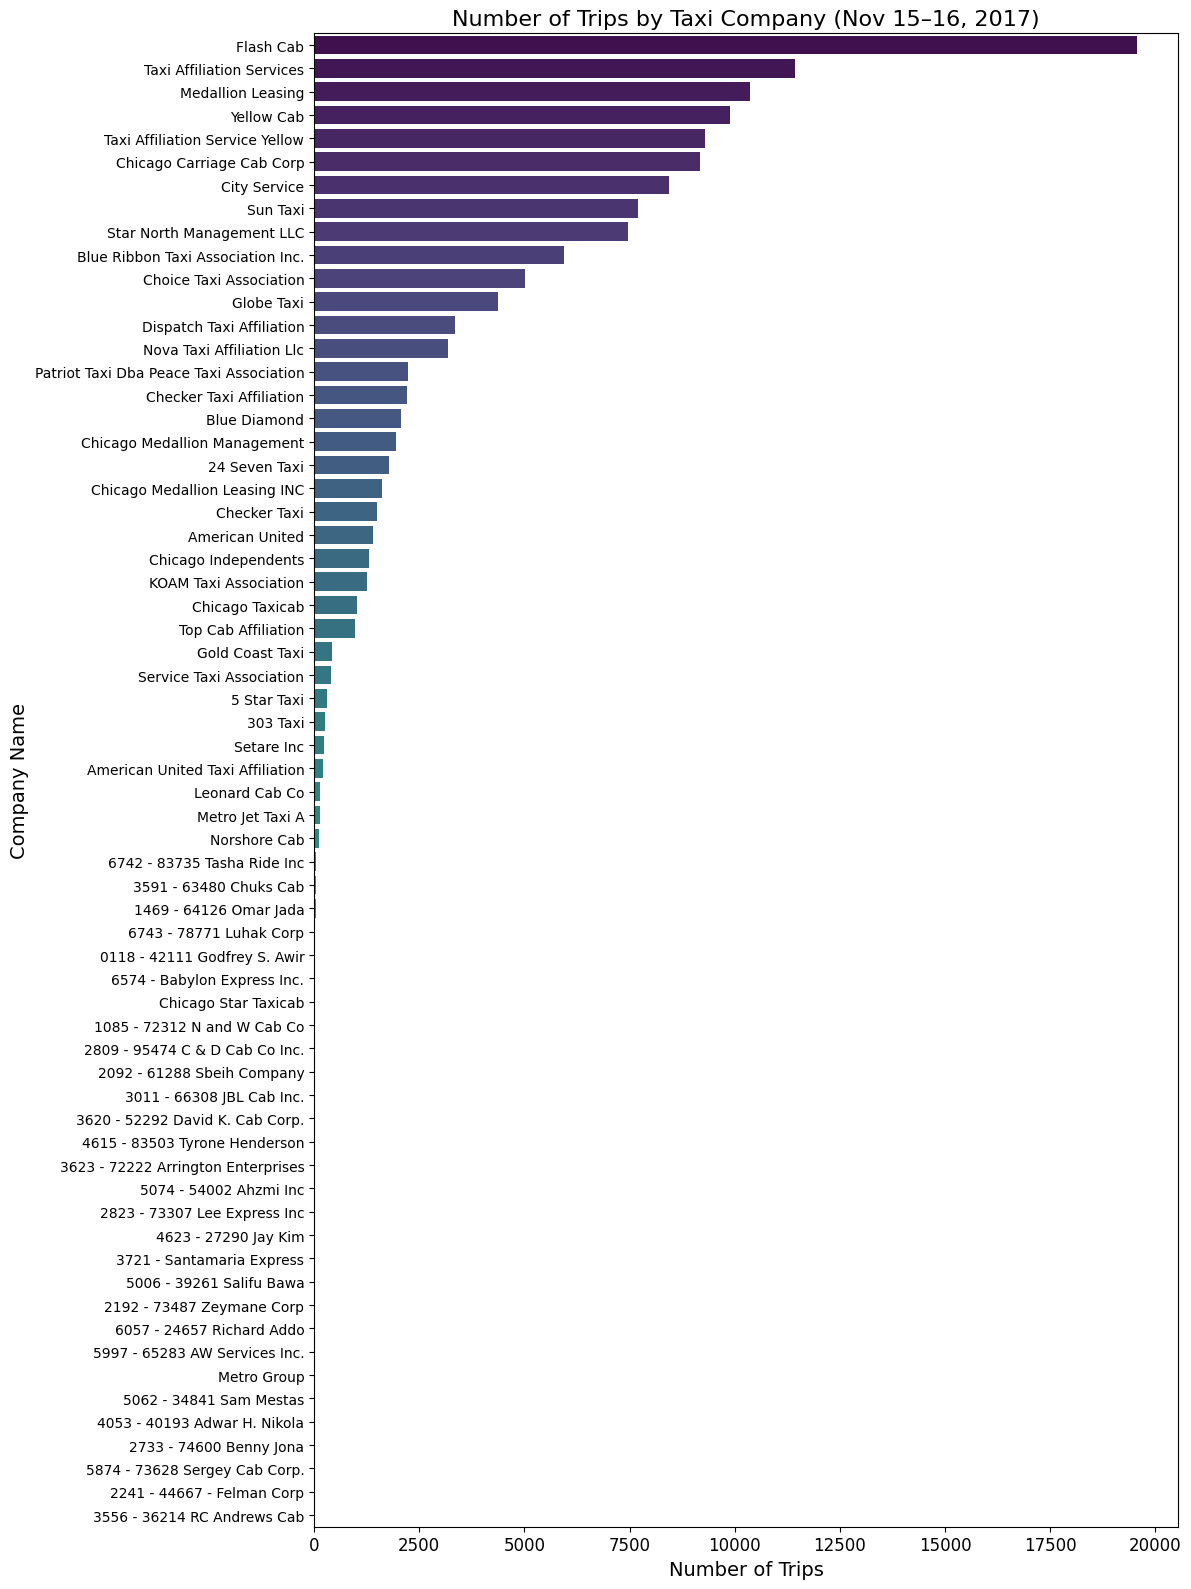

In [10]:
plt.figure(figsize=(12, 16))
sns.barplot(
    data=top_companies,
    x='trips_amount',
    y='company_name',
    palette='viridis'
)
plt.title('Number of Trips by Taxi Company (Nov 15–16, 2017)', fontsize=16)
plt.xlabel('Number of Trips', fontsize=14)
plt.ylabel('Company Name', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

Insights:
Flash Cab and Taxi Affiliation Services dominate the number of trips during this period.

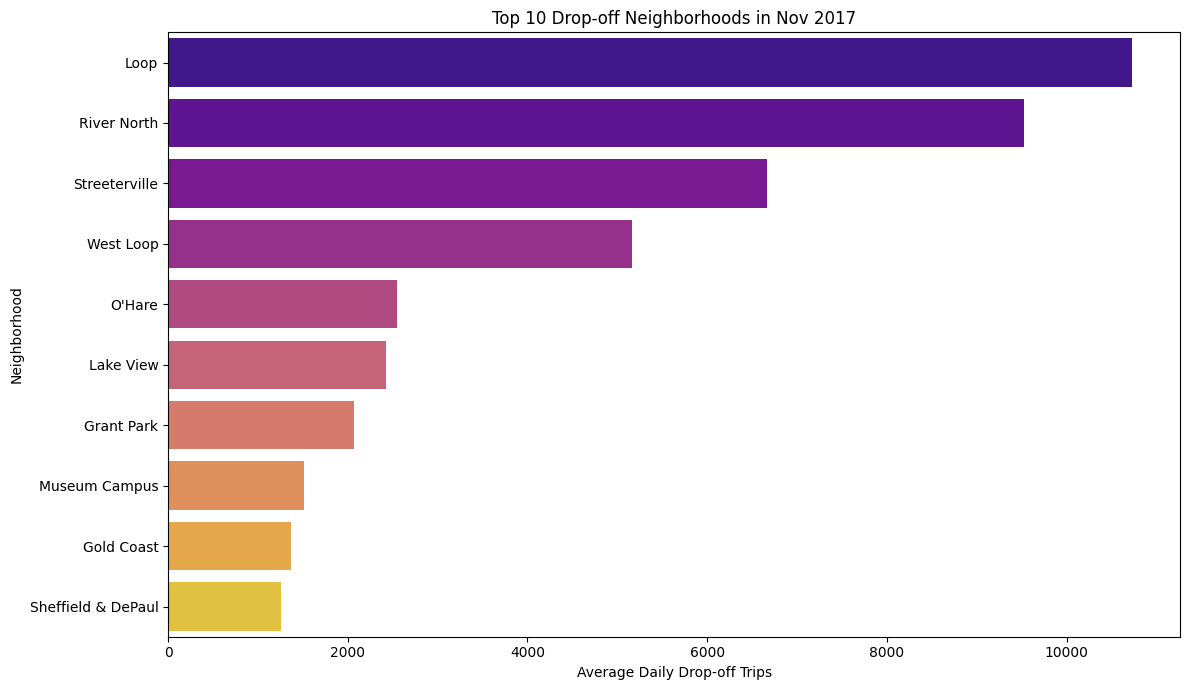

In [11]:
plt.figure(figsize=(12,7))
sns.barplot(data=top10, x='average_trips', y='dropoff_location_name', palette='plasma')
plt.title('Top 10 Drop-off Neighborhoods in Nov 2017')
plt.xlabel('Average Daily Drop-off Trips')
plt.ylabel('Neighborhood')
plt.tight_layout()
plt.show()

Insight:
-Loop and River North had the highest drop-off activity, indicating major business/tourist zones.

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
Well done! That looks great. 


In [12]:
df = pd.read_csv('/datasets/project_sql_result_07.csv', parse_dates=['start_ts'])
print(df.info())
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1068 entries, 0 to 1067
Data columns (total 3 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   start_ts            1068 non-null   datetime64[ns]
 1   weather_conditions  1068 non-null   object        
 2   duration_seconds    1068 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 25.2+ KB
None
             start_ts weather_conditions  duration_seconds
0 2017-11-25 16:00:00               Good            2410.0
1 2017-11-25 14:00:00               Good            1920.0
2 2017-11-25 12:00:00               Good            1543.0
3 2017-11-04 10:00:00               Good            2512.0
4 2017-11-11 07:00:00               Good            1440.0


In [13]:
duplicate_count = df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 197


In [14]:
# Drop duplicate rows in-place
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed. Remaining rows: {len(df)}")

Duplicates removed. Remaining rows: 871


In [15]:
df['start_ts'] = pd.to_datetime(df['start_ts'])
df['weekday'] = df['start_ts'].dt.day_name()
df['is_saturday'] = df['weekday'] == 'Saturday'
df['is_rainy'] = df['weather_conditions'].str.contains('rain', case=False, na=False)
df['rainy_saturday'] = (df['is_saturday']) & (df['weather_conditions'] == 'Bad')

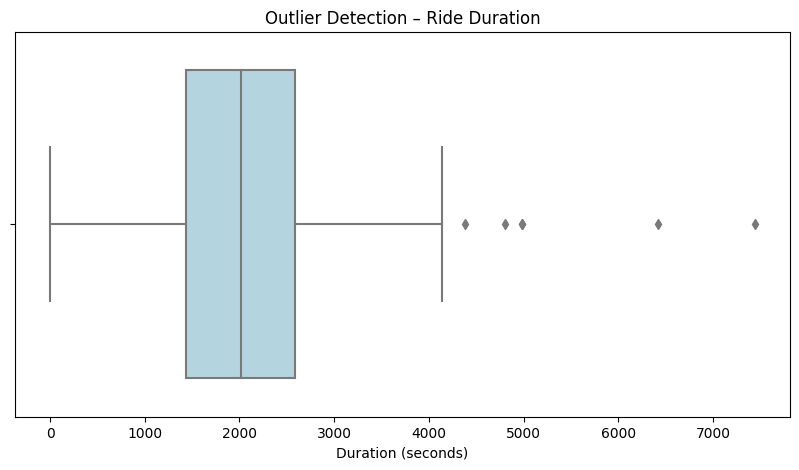

In [16]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['duration_seconds'], color='lightblue')
plt.title('Outlier Detection – Ride Duration')
plt.xlabel('Duration (seconds)')
plt.show()

In [17]:
Q1 = df['duration_seconds'].quantile(0.25)
Q3 = df['duration_seconds'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['duration_seconds'] < lower_bound) | (df['duration_seconds'] > upper_bound)]

print(f"Number of outliers: {len(outliers)}")
print(f"Outlier threshold: < {lower_bound:.1f} or > {upper_bound:.1f}")

Number of outliers: 6
Outlier threshold: < -276.0 or > 4300.0


<div style="background-color: #f8d7da; color: #721c24; padding: 15px; border-radius: 4px; border: 1px solid #f5c6cb;"> 


<b>Reviewer's comment v1</b>
 
Could you please make a quick check of `df` dataframe: duplicates & outliers.
    
Outliers can significantly affect the results of a two-sample t-test. Since the t-test compares the means of two groups, outliers can distort the mean and variance estimates, leading to unreliable test statistics and p-values. This distortion can result in an increased Type I error rate (incorrectly rejecting the null hypothesis) or reduced statistical power (failing to detect a true effect). 

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v2</b>
 
Thx! Well done!.

In [18]:
dur_rain_sat = df.loc[df['rainy_saturday'], 'duration_seconds']
dur_other = df.loc[~df['rainy_saturday'], 'duration_seconds']

In [19]:
print("Rainy Saturday Rides:", len(dur_rain_sat))
print("Other Rides:", len(dur_other))

Rainy Saturday Rides: 148
Other Rides: 723


In [20]:
# Inspect all unique weather descriptions on Saturdays
sat_weather = df[df['is_saturday']]['weather_conditions'].unique()
print("Unique weather conditions on Saturdays:\n", sat_weather)

Unique weather conditions on Saturdays:
 ['Good' 'Bad']



Test the hypothesis:
“The average duration of rides from the Loop to O’Hare Airport changes on rainy Saturdays.”

Hypotheses
	•	H₀ (Null): No difference in ride durations.
	•	H₁ (Alt): Ride durations do differ on rainy Saturdays.
	•	Significance Level (α): 0.05


In [21]:
# H0: There is no difference in average duration on bad-weather Saturdays vs others
# H1: There is a difference in average duration

alpha = 0.05

# Welch’s t-test (handles unequal variances and sample sizes)
t_stat, p_val = stats.ttest_ind(dur_rain_sat, dur_other, equal_var=False, nan_policy='omit')

print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_val:.5f}")

if p_val < alpha:
    print("Reject the null hypothesis — ride durations differ on rainy Saturdays.")
else:
    print("Fail to reject the null hypothesis — no significant difference found.")

T-statistic: 5.532
P-value: 0.00000
Reject the null hypothesis — ride durations differ on rainy Saturdays.


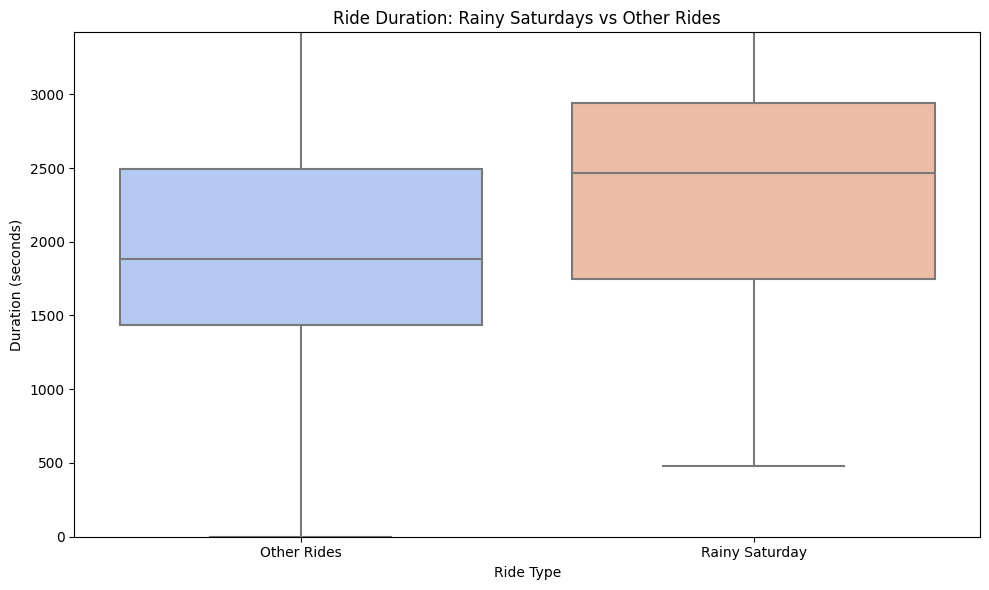

In [22]:
# Create a new column to label each category
df['ride_type'] = df['rainy_saturday'].map({True: 'Rainy Saturday', False: 'Other Rides'})

plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='ride_type', y='duration_seconds', palette='coolwarm')
plt.title('Ride Duration: Rainy Saturdays vs Other Rides')
plt.xlabel('Ride Type')
plt.ylabel('Duration (seconds)')
plt.ylim(0, df['duration_seconds'].quantile(0.95))  # limit to 95th percentile for better clarity
plt.tight_layout()
plt.show()

In [23]:
# Calculate IQR and define bounds
Q1 = df['duration_seconds'].quantile(0.25)
Q3 = df['duration_seconds'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filter out outliers
df_clean = df[(df['duration_seconds'] >= lower_bound) & (df['duration_seconds'] <= upper_bound)]

# Re-split cleaned data
rainy_clean = df_clean[df_clean['ride_type'] == 'Rainy Saturday']['duration_seconds']
other_clean = df_clean[df_clean['ride_type'] == 'Other Rides']['duration_seconds']

In [24]:
alpha = 0.05
t_stat, p_val = ttest_ind(rainy_clean, other_clean, equal_var=False, nan_policy='omit')

print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_val:.5f}")

if p_val < alpha:
    print("Reject the null hypothesis — durations differ even without outliers.")
else:
    print("Fail to reject the null hypothesis — no significant difference without outliers.")

T-statistic: 5.889
P-value: 0.00000
Reject the null hypothesis — durations differ even without outliers.


<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v2</b>
 
Well done!.

## Conclusions

- **Data Cleaning**: Duplicate rows (197) were removed and outliers were identified using the IQR method. The final dataset offers a more accurate foundation for analysis.
- **EDA Results**: Flash Cab and Taxi Affiliation Services led trip volumes, while the Loop, River North, and Streeterville had the most drop-offs, likely due to central business and tourist activity.
- **Statistical Testing**: 
  - After removing outliers, we re-tested the hypothesis comparing ride durations on rainy Saturdays vs. other days.
  - The p-value remained below 0.05, which confirms a **statistically significant difference** in ride durations during bad weather.
- **Business Insight**: This suggests that **weather significantly impacts ride duration**. Taxis (or platforms) may consider adjusting ETA predictions and pricing during rain, especially on weekends.

<div class="alert alert-warning">

<b>Reviewer's comment v1</b>
 
Here you can identify outliers in `duration_seconds`. Make a decision how to proceed with them before performing the hypothesis test. 

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v1</b>
 
The null and alternative hypotheses are clearly defined.
    
A two-sample t-test is used, which is the correct statistical test for comparing two groups (e.g., ride durations on good vs. bad weather Saturdays).
    
The significance level is explicitly mentioned, which is an important step in hypothesis testing.

<div style="background-color: #f8d7da; color: #721c24; padding: 15px; border-radius: 4px; border: 1px solid #f5c6cb;"> 


<b>Reviewer's comment v1</b>
 
Could you please add overall conclusions based on the previous insights? 

<div style="background-color: #d4edda; color: #155724; padding: 15px; border-radius: 4px; border: 1px solid #c3e6cb;">

<b>Reviewer's comment v2</b>
 
Thx! Amazing conclusions!.